# Linear regression

**Goal:** Understand the *create → fit → predict* workflow and how to judge a regression model.

**Data:** a toy example; a bank-loan dataset (850 customers); the Boston Housing dataset (506 houses, 13 features).

**Methods:** simple and multiple linear regression (scikit-learn), train/test split (70/30), MSE and R², coefficients and intercept, fixed-intercept models, predicting a new observation.

**Results**
| Model | R² |
|---|---|
| Income ~ age | 0.23 |
| Income ~ age + education + years employed | 0.51 |
| House price ~ 13 features (test set) | **0.71** (MSE 21.5) |

**Takeaway:** adding relevant features raised the explained variance of income from 23% to 51%. Evaluating on a held-out test set gives an honest picture of performance.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

### ***Regression***
### Linear Regression
### Logistic Regresion

## **Regression EXAMPLE**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression # we import only one function " LinerRegression from SKLEARN.
from sklearn import metrics # only imporfting one function


In [ ]:
x = np.arange(1,10) # we make an array from 1 to 9
y= np.array([28, 25, 26, 31, 32, 29, 30, 35, 36])

In [ ]:
x

array([[1],
       [2],
       [3],
       [4],
       [5],
       [6],
       [7],
       [8],
       [9]])

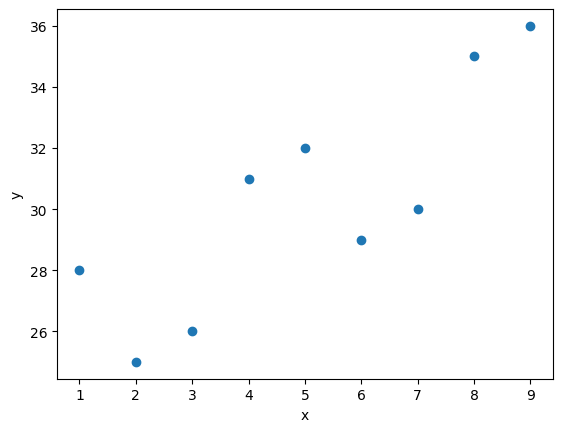

In [ ]:
#import matplotlib.pyplot as plt
plt.scatter(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### **Three** Steps for Machine Learning




## Creat Model
## Fit the Model
## Predict new data

In [ ]:
x.shape

(9,)

In [ ]:
x1 = x.reshape(-1,1) # -1 and 1 are arguments to reshape the array from row to column , because the machine knows a column as a variable not a row as variable
y1 = y.reshape(-1,1) # Do not use this code if you select your variable from the columns of a dataframe


In [ ]:
x1.shape

(9, 1)

In [ ]:
reg = LinearRegression() # Y = ax + b # Create Model

## Fit
Giving data to model to estimate the coefficent( slope) and intercept

In [ ]:
reg.fit(x1,y1) # fit the model

LinearRegression()

## Predict

In [ ]:
yhat = reg.predict(x) # predict

## We compare the result of regression with original data

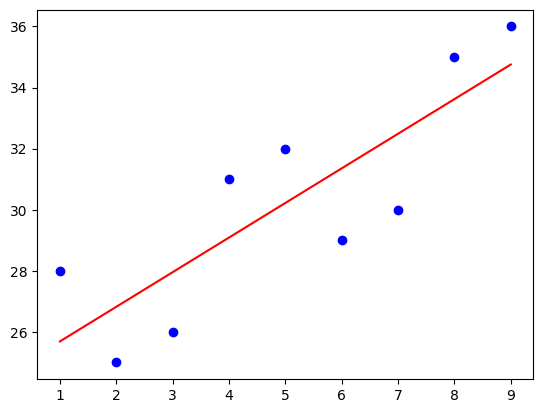

In [ ]:
plt.scatter(x,y, c='blue') # Original Data
plt.plot(x,yhat, c='red') # The result of Leaner Regression
plt.show()

In [ ]:
reg.coef_ # this is the slope of the line

array([[1.13333333]])

In [ ]:
reg.intercept_

array([24.55555556])

In [ ]:
df1=pd.read_csv('bank-loan.csv')
df1

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1.0
1,27,1,10,6,31,17.3,1.362202,4.000798,0.0
2,40,1,15,14,55,5.5,0.856075,2.168925,0.0
3,41,1,15,14,120,2.9,2.658720,0.821280,0.0
4,24,2,2,0,28,17.3,1.787436,3.056564,1.0
...,...,...,...,...,...,...,...,...,...
845,34,1,12,15,32,2.7,0.239328,0.624672,NaN
846,32,2,12,11,116,5.7,4.026708,2.585292,NaN
847,48,1,13,11,38,10.8,0.722304,3.381696,NaN
848,35,2,1,11,24,7.8,0.417456,1.454544,NaN


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       850 non-null    int64  
 1   ed        850 non-null    int64  
 2   employ    850 non-null    int64  
 3   address   850 non-null    int64  
 4   income    850 non-null    int64  
 5   debtinc   850 non-null    float64
 6   creddebt  850 non-null    float64
 7   othdebt   850 non-null    float64
 8   default   700 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 59.9 KB


In [ ]:
df1.head()

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1.0
1,27,1,10,6,31,17.3,1.362202,4.000798,0.0
2,40,1,15,14,55,5.5,0.856075,2.168925,0.0
3,41,1,15,14,120,2.9,2.658720,0.821280,0.0
4,24,2,2,0,28,17.3,1.787436,3.056564,1.0


In [ ]:
df1.describe()

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
count,850.000000,850.000000,850.000000,850.000000,850.000000,850.000000,850.000000,850.000000,700.000000
mean,35.029412,1.710588,8.565882,8.371765,46.675294,10.171647,1.576805,3.078789,0.261429
std,8.041432,0.927784,6.777884,6.895016,38.543054,6.719441,2.125840,3.398803,0.439727
min,20.000000,1.000000,0.000000,0.000000,13.000000,0.100000,0.011696,0.045584,0.000000
25%,29.000000,1.000000,3.000000,3.000000,24.000000,5.100000,0.382176,1.045942,0.000000
50%,34.000000,1.000000,7.000000,7.000000,35.000000,8.700000,0.885091,2.003243,0.000000
75%,41.000000,2.000000,13.000000,12.000000,55.750000,13.800000,1.898440,3.903001,1.000000
max,56.000000,5.000000,33.000000,34.000000,446.000000,41.300000,20.561310,35.197500,1.000000


In [ ]:
y2=df1[['income']] # we should put in two brakets to keep the strcutre as column of a dataframe not a pandas-series
x2=df1[['age']] # very important to put in two brakets



In [ ]:
reg1=LinearRegression() # Creat Model

In [ ]:
reg1.fit(x2,y2)# fit the model with my data (x,y)

LinearRegression()

In [ ]:
y2hat=reg1.predict(x2)

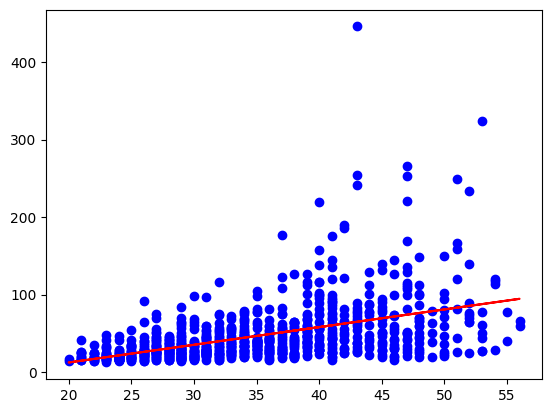

In [ ]:
plt.scatter(x2,y2, c='blue') # Original Data
plt.plot(x2,y2hat, c='red') # The result of Leaner Regression
plt.show()

In [ ]:
reg1.coef_

array([[2.28254123]])

In [ ]:
reg1.intercept_

array([-33.28078245])

In [ ]:
metrics.r2_score(y2, y2hat) # R2 which is an indicator to show the reliability and explanation power of linear regression

0.22678366354873314

In [ ]:
y3=df1[['income']] # very important ot have two brakets
x3=df1[['age','ed','employ']]

In [ ]:
x3

,age,ed,employ
0,41,3,17
1,27,1,10
2,40,1,15
3,41,1,15
4,24,2,2
...,...,...,...
845,34,1,12
846,32,2,12
847,48,1,13
848,35,2,1


In [ ]:
reg3=LinearRegression() # Creat Model
reg3.fit(x3,y3)# fit the model with my data (x,y)

LinearRegression()

In [ ]:
y3hat=reg3.predict(x3) # predicted y by x3

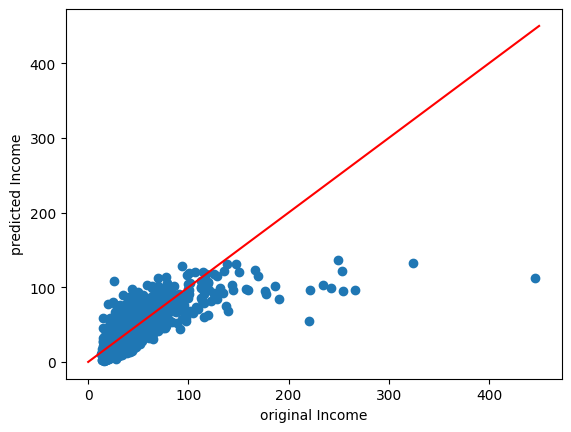

In [ ]:
plt.scatter(y3, y3hat)
plt.xlabel('original Income')
vv = [0,10,20,30,40,450] # reference line to show how these two amounts ( test and predicted) are different  )
plt.plot(vv,vv, color='red')
plt.ylabel('predicted Income')
plt.show()

In [ ]:
y3hat=reg3.predict(x3)
metrics.r2_score(y3, y3hat)

0.5050854481988416

In [ ]:
reg3.coef_

array([[ 0.69317703, 12.69855561,  3.36151362]])

In [ ]:

metrics.r2_score(y, yhat)

0.6908366533864543

In [ ]:
reg2 = LinearRegression(fit_intercept=False) # in this code , we creat a model with a condition : intercept = 0 , of course it is not the best regression , but sometime we decide special intercept for our regression
reg2.fit(x,y1)


LinearRegression(fit_intercept=False)

In [ ]:
reg2.intercept_

0.0

In [ ]:
reg3 = LinearRegression(fit_intercept=False) # first we calculate the regression based on intercept = 0 and then shift the model by adding the intercept till the desirde value
reg3.fit(x,y1)
y_ad = y1-3

In [ ]:
yhat=reg3.predict(x)

In [ ]:
y_ad=yhat+30

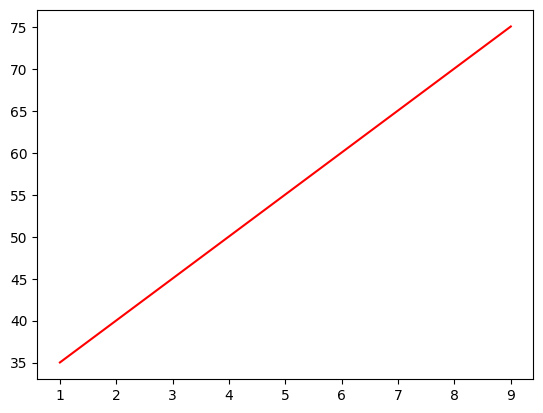

In [ ]:
plt.plot(x,y_ad, c='red') # The result of ML-Leaner Regression
plt.show()

In [ ]:
import pandas as pd
df3=pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv') # make dataframe

In [ ]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [ ]:
df3.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [ ]:
df3.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
x = df3.drop('medv', axis=1)# making a new dataframe with the 13 features of the houses in this dataset without medv , axis =1 means delete a column with the name medv
x.info() # new dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [ ]:
y=df3['medv'] # the price of the houses

In [ ]:
x

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48


In [ ]:
y

,medv
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2
...,...
501,22.4
502,20.6
503,23.9
504,22.0


# In this model we define 30 % of the data ( from 506) as test data.
# So the training phase of ML is done by 70 % data.
# The function is  "train_test_split"

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split (x, y, random_state=42, test_size = 0.3) # the random state is the seed number to fix our sample selection

**Creat Model**
**Fiting Phase**

We use the training proportion of data ( 70%) to make and fit the model.

In [ ]:
from sklearn.linear_model import LinearRegression # we import only one function " LinerRegression from SKLEARN.
from sklearn import metrics

In [ ]:
reg = LinearRegression() # we fit the model based on train sample # creat model
reg.fit(x_train, y_train) # fit the model


LinearRegression()

# **Priediction Phase**

# We put the X_test to get the prediction results and then we compare the results with original y_test which we keep to test whether our model is reliable or not

In [ ]:
y_pred = reg.predict(x_test)

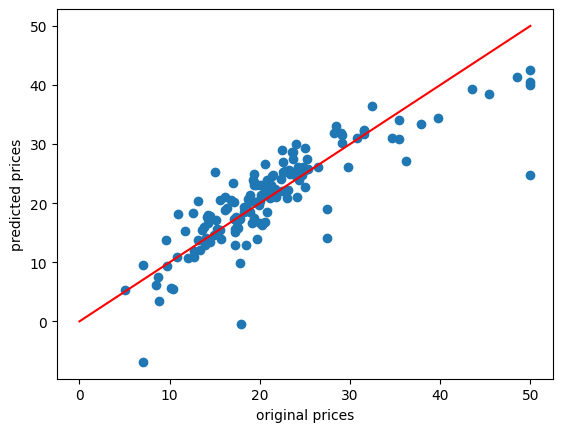

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel('original prices')
vv = [0,10,20,30,40,50] # reference line to show how these two amounts ( test and predicted) are different  )
plt.plot(vv,vv, color='red')
plt.ylabel('predicted prices')
plt.show()

# After Reression , we should check the reliablity of the model by two indicators which are:

# 1- MSE : a comparative indicator for our efort to find the best model for fitting


# 2- R square : which is an absolute indicator to show how our model fits the real data ( inoput data).

In [ ]:
from sklearn import metrics
mse = metrics.mean_squared_error(y_test, y_pred)
mse

21.517444231177183

### **R squre **

# R squre is a value between 0 and 1 and if it is near to 1 , it is better.

## R Square works only for linear regression , not for other types of regression like binarey logistic regression

In [ ]:

metrics.r2_score(y_test, y_pred)

0.7112260057484936

### ***Prediction of house price with 13 parametrs in Boston***

## in this line we give a  ( house) with 13 attributes

In [ ]:
x_new = np.array([0.00932, 18.0,	4.31,	0.0,	0.738,	3.575,	75.2,	5.0900,	1.0,	286.0,15.3,396.90,4.98]) # new house with its 13 features

In [ ]:
Predicted_Price = reg.predict([x_new])

Predicted_Price

array([13.52294652])

In [ ]:
reg.coef_

array([-1.33470103e-01,  3.58089136e-02,  4.95226452e-02,  3.11983512e+00,
       -1.54170609e+01,  4.05719923e+00, -1.08208352e-02, -1.38599824e+00,
        2.42727340e-01, -8.70223437e-03, -9.10685208e-01,  1.17941159e-02,
       -5.47113313e-01])

In [ ]:
reg.intercept_

np.float64(31.631084035693327)

Samples of dats

https://www.geeksforgeeks.org/machine-learning/dataset-for-linear-regression/